# SplitSnap v2 (Google Colab edition)
Donut fine-tuning on CORD + SROIE + synthetic Indian GST bills.


**Settings to know:** `SMOKE=True` is a quick pipeline test (saves to `splitsnap_smoke`). `EPOCHS=10` is about 2.5 hours at roughly 14 min/epoch on a T4.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!pip install -q -U transformers datasets sentencepiece accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 92.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 18.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
import json, re, os, io, csv, math, time, random
from difflib import SequenceMatcher
import numpy as np, pandas as pd, torch
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance
from datasets import load_dataset
from transformers import (DonutProcessor, VisionEncoderDecoderModel,
                          VisionEncoderDecoderConfig, get_cosine_schedule_with_warmup)


SMOKE = False        
USE_SROIE = True      
USE_SYNTH = True      
N_SYNTH = 800
RESUME_FROM = None    
AUTO_RESUME = True

BASE = "naver-clova-ix/donut-base"
IMG_H, IMG_W = 1280, 960       
MAX_LEN = 768                   
EPOCHS = 10
BATCH, ACCUM = 2, 8            
LR = 3e-5
WARMUP_FRAC = 0.05
AUG_P = 0.7
TIME_BUDGET_MIN = 230          
EVAL_EVERY, EVAL_N = 3, 16      
BASELINE_N = 20
LOW_CONF = 0.80                 
OUT_ROOT = "/content/drive/MyDrive"
SEED = 42

if SMOKE:
    EPOCHS, N_SYNTH, EVAL_EVERY, EVAL_N, BASELINE_N = 1, 40, 1, 4, 3

OUT = f"{OUT_ROOT}/splitsnap_{'smoke' if SMOKE else 'run1'}"
os.makedirs(OUT, exist_ok=True)
if RESUME_FROM is None and AUTO_RESUME and not SMOKE and os.path.exists(f"{OUT}/ckpt_last/state.pt"):
    RESUME_FROM = f"{OUT}/ckpt_last"
    print("auto-resuming from", RESUME_FROM)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
assert device == "cuda", "No GPU: Runtime > Change runtime type > T4 GPU, then run again"

auto-resuming from /content/drive/MyDrive/splitsnap_run1/ckpt_last
device: cuda


In [ ]:
cord = load_dataset("naver-clova-ix/cord-v2")
SOURCES = {f"cord_{k}": cord[k] for k in cord.keys()}      
if USE_SROIE:
    sroie = load_dataset("jsdnrs/ICDAR2019-SROIE")
    print(sroie)
    if "test" in sroie:
        SOURCES["sroie_train"], SOURCES["sroie_eval"] = sroie["train"], sroie["test"]
    else:
        sp = sroie["train"].train_test_split(test_size=0.1, seed=SEED)
        SOURCES["sroie_train"], SOURCES["sroie_eval"] = sp["train"], sp["test"]
    print("SROIE entities example:", SOURCES["sroie_train"][0]["entities"])
print({k: len(v) for k, v in SOURCES.items()})

README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00004-b4aaeceff1d90e(…): reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00004-b4aaeceff1d90e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-7dbbe248962764(…): reconstructing file:   0%|          |  0.00B /  441MB            

...

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  191MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/626 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/361 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'key', 'image_size', 'entities', 'words', 'bboxes'],
        num_rows: 626
    })
    test: Dataset({
        features: ['image', 'key', 'image_size', 'entities', 'words', 'bboxes'],
        num_rows: 361
    })
})
SROIE entities example: {'company': 'BOOK TA .K (TAMAN DAYA) SDN BHD', 'date': '25/12/2018', 'address': 'NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.', 'total': '9.00'}
{'cord_train': 800, 'cord_validation': 100, 'cord_test': 100, 'sroie_train': 626, 'sroie_eval': 361}


## Label conversion
CORD and SROIE use their own keys. Everything is mapped into the hackathon's JSON schema (items, charges, subtotal, grand_total). Print a few and check them by eye before trusting them.

In [ ]:
def num(s):

    if s is None:
        return None
    s = re.sub(r"[^\d.,]", "", str(s))
    if not s:
        return None
    if re.fullmatch(r"\d{1,3}([.,]\d{3})+", s):
        return int(re.sub(r"[.,]", "", s))
    if re.fullmatch(r"\d+[.,]\d{1,2}", s):
        return float(s.replace(",", "."))
    digits = re.sub(r"[.,]", "", s)
    return int(digits) if digits else None

def to_num(s):

    if s is None:
        return None
    s = str(s).strip()
    v = num(s)
    return None if v is None else (-v if s.startswith("-") else v)

def to_float(s):

    try:
        return float(re.sub(r"[^\d.]", "", str(s).replace(",", "")))
    except ValueError:
        return None

def clean(x):
    return int(x) if isinstance(x, float) and x.is_integer() else x

def cord_to_schema(gt):
    p = gt["gt_parse"]
    menu = p.get("menu", [])
    if isinstance(menu, dict):
        menu = [menu]
    items = []
    for m in menu:
        if not isinstance(m, dict):
            continue
        name = m.get("nm")
        qty = num(m.get("cnt")) or 1
        total = num(m.get("price"))
        unit = num(m.get("unitprice"))
        if unit is None and total is not None:
            unit = clean(round(total / qty, 2))
        if total is None and unit is not None:
            total = clean(unit * qty)
        if not name or isinstance(name, list) or total is None:
            continue
        items.append({"name": str(name).strip(), "qty": clean(qty), "unit_price": unit, "total": total})
    st = p.get("sub_total", {})
    st = st if isinstance(st, dict) else {}
    charges = []
    for key, label, sign in [("tax_price", "Tax", 1), ("service_price", "Service Charge", 1),
                             ("discount_price", "Discount", -1)]:
        v = num(st.get(key))
        if v:
            charges.append({"type": label, "amount": sign * v})
    out = {"items": items, "charges": charges}
    sub = num(st.get("subtotal_price"))
    tot = p.get("total", {})
    grand = num(tot.get("total_price")) if isinstance(tot, dict) else None
    if sub is not None:
        out["subtotal"] = sub
    if grand is not None:
        out["grand_total"] = grand
    return out

def sroie_to_target(ent):
    out = {}
    for k in ["company", "date", "address", "total"]:
        v = ent.get(k) if isinstance(ent, dict) else None
        if v:
            out[k] = re.sub(r"\s+", " ", str(v)).strip()
    return out if out.get("total") else None

for i in range(3):
    print(json.dumps(cord_to_schema(json.loads(SOURCES["cord_train"][i]["ground_truth"])))[:500])

{"items": [{"name": "Nasi Campur Bali", "qty": 1, "unit_price": 75000, "total": 75000}, {"name": "Bbk Bengil Nasi", "qty": 1, "unit_price": 125000, "total": 125000}, {"name": "MilkShake Starwb", "qty": 1, "unit_price": 37000, "total": 37000}, {"name": "Ice Lemon Tea", "qty": 1, "unit_price": 24000, "total": 24000}, {"name": "Nasi Ayam Dewata", "qty": 1, "unit_price": 70000, "total": 70000}, {"name": "Free Ice Tea", "qty": 3, "unit_price": 0, "total": 0}, {"name": "Organic Green Sa", "qty": 1, "u
{"items": [{"name": "SPGTHY BOLOGNASE", "qty": 1, "unit_price": 58000, "total": 58000}, {"name": "PEPPER AUS", "qty": 1, "unit_price": 165000, "total": 165000}, {"name": "WAGYU RIBEYE", "qty": 1, "unit_price": 195000, "total": 195000}, {"name": "ICED LEMON TEA", "qty": 1, "unit_price": 22000, "total": 22000}, {"name": "FUSION TEA LYCHE", "qty": 1, "unit_price": 28000, "total": 28000}, {"name": "NUTTELA BROWNIES", "qty": 1, "unit_price": 35000, "total": 35000}], "charges": [{"type": "Tax", "amou

## Synthetic Indian GST bills
Item names, rupee prices, CGST/SGST at 2.5/6/9 percent, optional service charge, discount and round-off, rendered with varied fonts, paper tones and layouts. Ground truth is exact by construction. This is the "light synthetic augmentation" the PS allows, taken one step further, so mention it openly in the report.

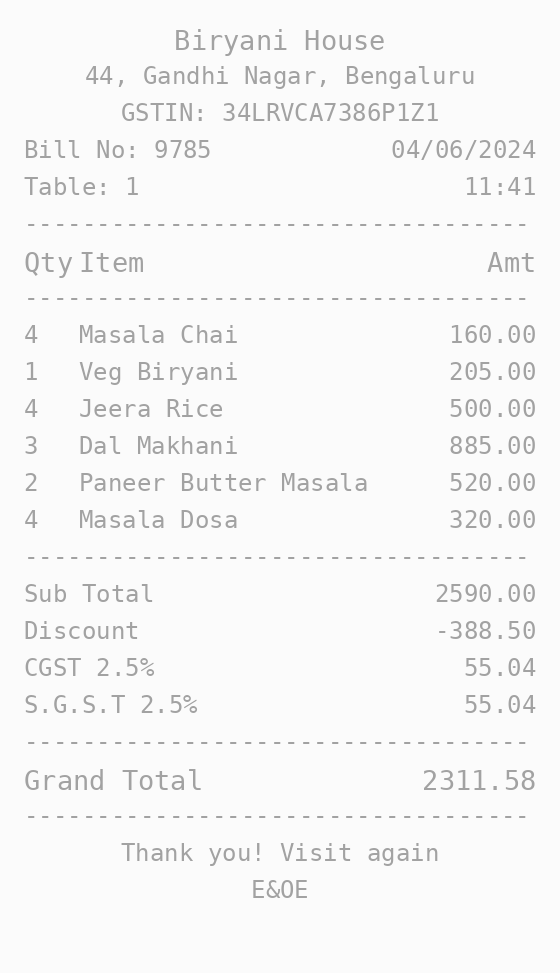

In [ ]:
import matplotlib
FONT_DIR = os.path.join(matplotlib.get_data_path(), "fonts", "ttf")
FONTS = [os.path.join(FONT_DIR, f) for f in ["DejaVuSansMono.ttf", "DejaVuSans.ttf", "DejaVuSerif.ttf"]]

MENU = [("Paneer Butter Masala",200,340),("Dal Makhani",160,300),("Veg Biryani",180,320),
 ("Chicken Biryani",220,380),("Butter Naan",35,70),("Garlic Naan",40,80),("Tandoori Roti",15,35),
 ("Jeera Rice",110,190),("Masala Dosa",80,160),("Idli Sambar",60,110),("Chole Bhature",90,170),
 ("Veg Fried Rice",140,240),("Hakka Noodles",140,240),("Gobi Manchurian",150,250),
 ("Chilli Paneer",190,300),("Palak Paneer",190,320),("Kadai Chicken",260,420),
 ("Mutton Rogan Josh",340,520),("Cold Coffee",90,170),("Masala Chai",20,50),
 ("Fresh Lime Soda",50,110),("Sweet Lassi",60,120),("Mango Shake",90,160),("Gulab Jamun",50,110),
 ("Rasmalai",70,130),("Veg Thali",120,240),("Egg Curry",120,220),("Aloo Paratha",50,100),
 ("Paneer Tikka",200,330),("Tomato Soup",80,150),("Dahi Vada",60,120),("Pav Bhaji",100,180),
 ("Veg Momos",80,150),("Roomali Roti",25,50),("Mineral Water",20,40),("Filter Coffee",30,70)]
PLACES = ["Annapurna Mess","Spice Route","Hostel Canteen Block C","Tandoor Tales","Dosa Corner",
          "Punjabi Rasoi","Campus Cafe","Biryani House","Chai Point","Saffron Kitchen"]
STREETS = ["MG Road","Station Road","Civil Lines","College Road","Park Street","Gandhi Nagar","Ring Road"]
CITIES = ["Guwahati","Pune","Jaipur","Bengaluru","Lucknow","Kolkata","Hyderabad","Indore"]

def fmt_num(x):
    x = round(float(x), 2)
    return int(x) if x == int(x) else x

def make_spec(seed):
    rng = random.Random(seed)
    items = []
    for name, lo, hi in rng.sample(MENU, rng.randint(2, 8)):
        qty = rng.choice([1, 1, 1, 2, 2, 3, 4])
        unit = rng.randrange(lo, hi + 1, 5)
        items.append({"name": name, "qty": qty, "unit_price": unit, "total": unit * qty})
    subtotal = sum(i["total"] for i in items)
    charges, base = [], float(subtotal)
    disc_pct = rng.choice([5, 10, 15, 20])
    if rng.random() < 0.25:
        d = round(subtotal * disc_pct / 100, 2)
        charges.append({"type": "Discount", "amount": fmt_num(-d)})
        base -= d
    if rng.random() < 0.45:
        sc = round(base * 0.10, 2)
        charges.append({"type": "Service Charge", "amount": fmt_num(sc)})
        base += sc
    rate = rng.choice([2.5, 2.5, 6, 9])
    gst = round(base * rate / 100, 2)
    charges += [{"type": "CGST", "amount": fmt_num(gst)}, {"type": "SGST", "amount": fmt_num(gst)}]
    total = base + 2 * gst
    if rng.random() < 0.5:
        rounded = round(total)
        ro = round(rounded - total, 2)
        if ro:
            charges.append({"type": "Round Off", "amount": fmt_num(ro)})
        total = rounded
    gt = {"items": items, "charges": charges, "subtotal": fmt_num(subtotal),
          "grand_total": fmt_num(round(total, 2))}
    return {"seed": seed, "rate": rate, "disc_pct": disc_pct, "gt": gt}

def render_bill(spec, rng):
    gt, r = spec["gt"], spec["rate"]
    fp, fs = rng.choice(FONTS), rng.choice([20, 22, 24])
    f, fb = ImageFont.truetype(fp, fs), ImageFont.truetype(fp, fs + 3)
    W, pad, lh = rng.choice([560, 620, 700]), 24, int(fs * 1.55)
    layout = rng.choice("ab")
    n_lines = 16 + len(gt["items"]) + len(gt["charges"])
    H = 2 * pad + lh * n_lines
    paper = rng.choice([(255, 255, 255), (250, 247, 238), (244, 244, 244)])
    ink = rng.choice([(20, 20, 20), (40, 40, 40), (70, 70, 70), (95, 95, 95)])
    img = Image.new("RGB", (W, H), paper)
    d = ImageDraw.Draw(img)
    st = {"y": pad}
    money = lambda x: f"{x:.2f}"
    tl = lambda t, ft: d.textlength(t, font=ft)

    def center(t, ft):
        d.text(((W - tl(t, ft)) / 2, st["y"]), t, font=ft, fill=ink); st["y"] += lh
    def sep():
        d.text((pad, st["y"]), "-" * int((W - 2 * pad) / tl("-", f)), font=f, fill=ink); st["y"] += lh
    def lr(l, rt, ft=f):
        d.text((pad, st["y"]), l, font=ft, fill=ink)
        d.text((W - pad - tl(rt, ft), st["y"]), rt, font=ft, fill=ink); st["y"] += lh

    gstin = (f"{rng.randint(10, 37)}" + "".join(rng.choices("ABCDEFGHJKLMNPRSTUVWXYZ", k=5)) +
             f"{rng.randint(1000, 9999)}" + rng.choice("ABCDEFGHJKLMNPRSTUVWXYZ") + "1Z" + rng.choice("123456789"))
    center(rng.choice(PLACES), fb)
    center(f"{rng.randint(10, 99)}, {rng.choice(STREETS)}, {rng.choice(CITIES)}", f)
    center("GSTIN: " + gstin, f)
    lr(f"Bill No: {rng.randint(100, 9999)}",
       f"{rng.randint(1, 28):02d}/{rng.randint(1, 12):02d}/{rng.choice([2024, 2025, 2026])}")
    lr(f"Table: {rng.randint(1, 30)}", f"{rng.randint(11, 23)}:{rng.randint(0, 59):02d}")
    sep()
    xq, xr = int(W * 0.62), int(W * 0.80)
    if layout == "a":
        d.text((pad, st["y"]), "Item", font=fb, fill=ink); d.text((xq, st["y"]), "Qty", font=fb, fill=ink)
        d.text((xr - tl("Rate", fb), st["y"]), "Rate", font=fb, fill=ink)
    else:
        d.text((pad, st["y"]), "Qty", font=fb, fill=ink); d.text((pad + 55, st["y"]), "Item", font=fb, fill=ink)
    d.text((W - pad - tl("Amt", fb), st["y"]), "Amt", font=fb, fill=ink); st["y"] += lh
    sep()
    for it in gt["items"]:
        y = st["y"]
        if layout == "a":
            d.text((pad, y), it["name"], font=f, fill=ink); d.text((xq, y), str(it["qty"]), font=f, fill=ink)
            ru = money(it["unit_price"]); d.text((xr - tl(ru, f), y), ru, font=f, fill=ink)
        else:
            d.text((pad, y), str(it["qty"]), font=f, fill=ink); d.text((pad + 55, y), it["name"], font=f, fill=ink)
        am = money(it["total"]); d.text((W - pad - tl(am, f), y), am, font=f, fill=ink); st["y"] += lh
    sep()
    lr("Sub Total", money(gt["subtotal"]))
    for c in gt["charges"]:
        t = c["type"]
        if t in ("CGST", "SGST"):
            lab = rng.choice([f"{t} @{r}%", f"{t} {r}%", ".".join(t) + f" {r}%"])
        elif t == "Service Charge":
            lab = rng.choice(["Service Charge", "Service Charge 10%", "Service Chg 10%"])
        elif t == "Discount":
            lab = rng.choice(["Discount", f"Disc @{spec['disc_pct']}%"])
        else:
            lab = rng.choice(["Round Off", "Rounding"])
        lr(lab, money(c["amount"]))
    sep()
    lr(rng.choice(["Grand Total", "Total Amount", "Net Payable"]), money(gt["grand_total"]), fb)
    sep()
    center("Thank you! Visit again", f)
    center("E&OE", f)
    if rng.random() < 0.6:   
        m, bg = rng.randint(20, 120), rng.choice([(90, 70, 50), (150, 130, 110), (60, 60, 65), (170, 170, 170), (120, 100, 80)])
        canvas = Image.new("RGB", (W + 2 * m, H + 2 * m), bg)
        canvas.paste(img, (m, m)); img = canvas
    return img

def augment(img, rng):
    if rng.random() < 0.5:
        img = img.rotate(rng.uniform(-6, 6), expand=True, fillcolor=(255, 255, 255), resample=Image.BICUBIC)
    if rng.random() < 0.4:
        img = ImageEnhance.Brightness(img).enhance(rng.uniform(0.6, 1.3))
    if rng.random() < 0.4:
        img = ImageEnhance.Contrast(img).enhance(rng.uniform(0.5, 1.2))
    if rng.random() < 0.3:
        img = img.filter(ImageFilter.GaussianBlur(rng.uniform(0.5, 1.6)))
    if rng.random() < 0.3:
        buf = io.BytesIO(); img.save(buf, "JPEG", quality=rng.randint(25, 70)); buf.seek(0)
        img = Image.open(buf).convert("RGB")
    return img

if USE_SYNTH:
    try:
        from IPython.display import display
        display(augment(render_bill(make_spec(10_000), random.Random(1)), random.Random(2)))
    except Exception as e:
        print("preview skipped:", e)

In [11]:
TASK = {"bill": "<s_splitsnap>", "sroie": "<s_sroie>"}
specials = set(TASK.values()) | {"<sep/>"}

def json2token(obj):
    if isinstance(obj, dict):
        out = ""
        for k, v in obj.items():
            specials.update({f"<s_{k}>", f"</s_{k}>"})
            out += f"<s_{k}>{json2token(v)}</s_{k}>"
        return out
    if isinstance(obj, list):
        return "<sep/>".join(json2token(x) for x in obj)
    return str(obj)

LIM = 40 if SMOKE else None
RECS = {}

def build_cord(split, name):
    out = []
    for i, g in enumerate(SOURCES[f"cord_{split}"]["ground_truth"]):
        schema = cord_to_schema(json.loads(g))
        if schema["items"]:
            out.append({"src": f"cord_{split}", "i": i, "task": "bill", "gt": schema,
                        "text": TASK["bill"] + json2token(schema)})
    RECS[name] = out[:LIM]

def build_sroie(key, name):
    out = []
    for i, ent in enumerate(SOURCES[key]["entities"]):
        t = sroie_to_target(ent)
        if t:
            out.append({"src": key, "i": i, "task": "sroie", "gt": t, "text": TASK["sroie"] + json2token(t)})
    RECS[name] = out[:LIM]

build_cord("train", "cord_train"); build_cord("validation", "cord_val"); build_cord("test", "cord_test")
if USE_SROIE:
    build_sroie("sroie_train", "sroie_train"); build_sroie("sroie_eval", "sroie_eval")
if USE_SYNTH:
    syn = [{"src": "synth", "i": s, "spec": sp, "task": "bill", "gt": sp["gt"],
            "text": TASK["bill"] + json2token(sp["gt"])}
           for s, sp in enumerate(make_spec(10_000 + s) for s in range(N_SYNTH))]
    cut = int(len(syn) * 0.9)
    RECS["synth_train"], RECS["synth_val"] = syn[:cut], syn[cut:]
print({k: len(v) for k, v in RECS.items()})
print(RECS["cord_train"][0]["text"][:300])

{'cord_train': 792, 'cord_val': 100, 'cord_test': 100, 'sroie_train': 625, 'sroie_eval': 361, 'synth_train': 720, 'synth_val': 80}
<s_splitsnap><s_items><s_name>Nasi Campur Bali</s_name><s_qty>1</s_qty><s_unit_price>75000</s_unit_price><s_total>75000</s_total><sep/><s_name>Bbk Bengil Nasi</s_name><s_qty>1</s_qty><s_unit_price>125000</s_unit_price><s_total>125000</s_total><sep/><s_name>MilkShake Starwb</s_name><s_qty>1</s_qty><s


In [ ]:
SRC_MODEL = RESUME_FROM or BASE
processor = DonutProcessor.from_pretrained(SRC_MODEL)
processor.image_processor.size = {"height": IMG_H, "width": IMG_W}
processor.image_processor.do_align_long_axis = False
tok = processor.tokenizer
tok.add_tokens(sorted(specials))

config = VisionEncoderDecoderConfig.from_pretrained(SRC_MODEL)
config.encoder.image_size = [IMG_H, IMG_W]
config.decoder.max_length = MAX_LEN
model = VisionEncoderDecoderModel.from_pretrained(SRC_MODEL, config=config)
model.decoder.resize_token_embeddings(len(tok))

PAD_ID, EOS_ID, UNK_ID = tok.pad_token_id, tok.eos_token_id, tok.unk_token_id
TASK_ID = {k: tok.convert_tokens_to_ids(v) for k, v in TASK.items()}
model.config.pad_token_id, model.config.eos_token_id = PAD_ID, EOS_ID
model.config.decoder_start_token_id = TASK_ID["bill"]
model.to(device)

dropped, lens = 0, []
for name in list(RECS):
    keep = []
    for r in RECS[name]:
        ids = tok(r["text"], add_special_tokens=False).input_ids + [EOS_ID]
        r["ids"] = ids
        lens.append(len(ids))
        if name.endswith("train") and len(ids) > MAX_LEN + 1:
            dropped += 1
            continue
        keep.append(r)
    RECS[name] = keep
print("target tokens p50/p90/p99:", np.percentile(lens, [50, 90, 99]).astype(int), "| dropped from train:", dropped)

Loading weights:   0%|          | 0/483 [00:00<?, ?it/s]

target tokens p50/p90/p99: [ 64 152 208] | dropped from train: 0


In [ ]:
def load_image(r):
    if r["src"] == "synth":
        return render_bill(r["spec"], random.Random(r["spec"]["seed"])).convert("RGB")
    if r["src"] == "file":
        return Image.open(r["path"]).convert("RGB")
    return SOURCES[r["src"]][r["i"]]["image"].convert("RGB")

class MixDS(torch.utils.data.Dataset):
    def __init__(self, recs, train):
        self.recs, self.train = recs, train
    def __len__(self):
        return len(self.recs)
    def __getitem__(self, k):
        r = self.recs[k]
        img = load_image(r)
        img.thumbnail((2400, 2400))
        if self.train and random.random() < AUG_P:
            img = augment(img, random)
        pv = processor.image_processor(img, return_tensors="pt").pixel_values.squeeze(0)
        ids = r["ids"][:MAX_LEN + 1]
        n = len(ids) - 1
        dec = torch.full((MAX_LEN,), PAD_ID, dtype=torch.long)
        lab = torch.full((MAX_LEN,), -100, dtype=torch.long)
        dec[:n] = torch.tensor(ids[:-1])  
        lab[:n] = torch.tensor(ids[1:])     
        return {"pixel_values": pv, "decoder_input_ids": dec, "labels": lab}

## Inference, confidence and metrics
- `infer` generates greedily and keeps each token's probability.
- `field_conf` turns token probabilities into one score per field (`items[2].total`, `grand_total`, ...).
- `score` compares a prediction with ground truth field by field. A calibration table later shows whether low confidence really means more errors (R2 bonus evidence).

In [ ]:
from tqdm.auto import tqdm

@torch.no_grad()
def infer(img, task="bill"):
    model.eval()
    pv = processor.image_processor(img.convert("RGB"), return_tensors="pt").pixel_values.to(device)
    dec = torch.tensor([[TASK_ID[task]]], device=device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
        out = model.generate(pv, decoder_input_ids=dec, max_length=MAX_LEN, pad_token_id=PAD_ID,
                             eos_token_id=EOS_ID, use_cache=True, num_beams=1, do_sample=False,
                             bad_words_ids=[[UNK_ID]], return_dict_in_generate=True, output_scores=True)
    lp = model.compute_transition_scores(out.sequences, out.scores, normalize_logits=True)[0]
    probs = lp.float().exp().tolist()
    gen = out.sequences[0][1:].tolist()[:len(probs)]
    return gen, probs

def field_conf(toks, probs):
    stack, bag = [], {}
    for t, p in zip(toks, probs):
        if re.fullmatch(r"<s_[^>]+>", t):
            stack.append([t[3:-1], 0])
        elif re.fullmatch(r"</s_[^>]+>", t):
            if stack:
                stack.pop()
        elif t == "<sep/>":
            if stack:
                stack[-1][1] += 1
        elif stack:
            path = ".".join([f"{k}[{i}]" for k, i in stack[:-1]] + [stack[-1][0]])
            bag.setdefault(path, []).append(p)
    return {k: {"mean": float(np.exp(np.mean(np.log(np.clip(v, 1e-9, 1))))), "min": float(min(v))}
            for k, v in bag.items()}

def decode(gen, probs):
    toks = tok.convert_ids_to_tokens(gen)
    cut = toks.index(tok.eos_token) if tok.eos_token in toks else len(toks)
    toks, probs, gen = toks[:cut], probs[:cut], gen[:cut]
    seq = tok.decode(gen, skip_special_tokens=False)
    try:
        js = processor.token2json(seq)
    except Exception:
        js = None
    return js, field_conf(toks, probs), seq

def norm_pred(js):
    if not isinstance(js, dict):
        return None
    as_list = lambda x: x if isinstance(x, list) else ([x] if isinstance(x, dict) else [])
    items = [{"name": str(i.get("name", "")).strip(), "qty": to_num(i.get("qty")),
              "unit_price": to_num(i.get("unit_price")), "total": to_num(i.get("total"))}
             for i in as_list(js.get("items")) if isinstance(i, dict)]
    charges = [{"type": str(c.get("type", "")).strip(), "amount": to_num(c.get("amount"))}
               for c in as_list(js.get("charges")) if isinstance(c, dict)]
    return {"items": items, "charges": charges,
            "subtotal": to_num(js.get("subtotal")), "grand_total": to_num(js.get("grand_total"))}

def same(a, b, tol=0.01):
    return a is not None and b is not None and abs(a - b) <= tol

def sim(a, b):
    return SequenceMatcher(None, a.lower().strip(), b.lower().strip()).ratio()

def score(pred, gt):
    m = dict(valid=bool(pred and pred["items"]), item_tp=0, item_pred=0, item_gt=len(gt["items"]),
             ch_tp=0, ch_pred=0, ch_gt=len(gt["charges"]), sub_ok=None, tot_ok=None, consistent=False)
    ok = {}
    if pred is None:
        return m, ok

    used, matched = set(), {}
    for pi, p in enumerate(pred["items"]):
        best, bj = 0.0, None
        for j, g in enumerate(gt["items"]):
            if j not in used and sim(p["name"], g["name"]) > best:
                best, bj = sim(p["name"], g["name"]), j
        if bj is not None and best >= 0.75:
            used.add(bj); matched[pi] = bj
    m["item_pred"] = len(pred["items"])
    for pi, p in enumerate(pred["items"]):
        if pi in matched:
            g = gt["items"][matched[pi]]
            f = {"name": True, "qty": same(p["qty"], g["qty"], 1e-6),
                 "unit_price": same(p["unit_price"], g["unit_price"]), "total": same(p["total"], g["total"])}
            m["item_tp"] += int(f["qty"] and f["total"])
        else:
            f = {k: False for k in ("name", "qty", "unit_price", "total")}
        for k, v in f.items():
            ok[f"items[{pi}].{k}"] = v
    used = set()
    m["ch_pred"] = len(pred["charges"])
    for ci, c in enumerate(pred["charges"]):
        hit = next((j for j, g in enumerate(gt["charges"]) if j not in used
                    and c["type"].lower() == g["type"].lower() and same(c["amount"], g["amount"])), None)
        if hit is not None:
            used.add(hit); m["ch_tp"] += 1
        ok[f"charges[{ci}].type"] = ok[f"charges[{ci}].amount"] = hit is not None
    if gt.get("subtotal") is not None:
        m["sub_ok"] = ok["subtotal"] = same(pred["subtotal"], gt["subtotal"])
    if gt.get("grand_total") is not None:
        m["tot_ok"] = ok["grand_total"] = same(pred["grand_total"], gt["grand_total"])
    s = sum(i["total"] or 0 for i in pred["items"]) + sum(c["amount"] or 0 for c in pred["charges"])
    m["consistent"] = pred["grand_total"] is not None and abs(s - pred["grand_total"]) <= 1.0
    return m, ok

def aggregate(ms):
    def prf(tp, p, g):
        pr, rc = (tp / p if p else 0.0), (tp / g if g else 0.0)
        return round(pr, 4), round(rc, 4), round(2 * pr * rc / (pr + rc), 4) if pr + rc else 0.0
    S = lambda k: sum(m[k] for m in ms)
    acc = lambda k: (round(float(np.mean([m[k] for m in ms if m[k] is not None])), 4)
                     if any(m[k] is not None for m in ms) else None)
    ip, ir, i_f = prf(S("item_tp"), S("item_pred"), S("item_gt"))
    cp, cr, c_f = prf(S("ch_tp"), S("ch_pred"), S("ch_gt"))
    return {"n": len(ms), "valid_json_rate": round(float(np.mean([m["valid"] for m in ms])), 4),
            "item_P": ip, "item_R": ir, "item_F1": i_f, "charge_P": cp, "charge_R": cr, "charge_F1": c_f,
            "subtotal_acc": acc("sub_ok"), "grand_total_acc": acc("tot_ok"),
            "pred_arith_consistent": round(float(np.mean([m["consistent"] for m in ms])), 4)}

def eval_records(recs, n=None):
    recs = recs[:n] if n else recs
    ms, cal, outs = [], [], []
    for r in tqdm(recs):
        gen, probs = infer(load_image(r), "bill")
        js, conf, seq = decode(gen, probs)
        pred = norm_pred(js)
        m, ok = score(pred, r["gt"])
        ms.append(m)
        cal += [(conf[p]["min"], bool(v)) for p, v in ok.items() if p in conf]
        outs.append({"pred": pred, "gt": r["gt"], "conf": conf, "raw": seq})
    return aggregate(ms), cal, outs

def calibration(cal):
    rows = []
    for lo, hi in [(0, .5), (.5, .8), (.8, .95), (.95, 1.01)]:
        sel = [ok for c, ok in cal if lo <= c < hi]
        rows.append({"min_token_conf": f"{lo:.2f}-{min(hi, 1):.2f}", "fields": len(sel),
                     "accuracy": round(float(np.mean(sel)), 3) if sel else None})
    return pd.DataFrame(rows)

norm_txt = lambda s: re.sub(r"\s+", " ", str(s)).strip().lower()

def eval_sroie(n=None):
    recs = RECS["sroie_eval"][:n] if n else RECS["sroie_eval"]
    hits = {k: [] for k in ["company", "date", "address", "total"]}
    for r in tqdm(recs):
        gen, probs = infer(load_image(r), "sroie")
        js, _, _ = decode(gen, probs)
        js = js if isinstance(js, dict) else {}
        for k in hits:
            if k not in r["gt"]:
                continue
            pv = js.get(k)
            hits[k].append(same(to_float(pv), to_float(r["gt"][k])) if k == "total"
                           else norm_txt(pv) == norm_txt(r["gt"][k]))
    return {k: round(float(np.mean(v)), 4) for k, v in hits.items() if v}

## "Before" baseline
Same model, same prompt, no training. The PS requires before/after numbers, and this cannot be recovered after training. Expect values near zero.

In [ ]:
bpath = f"{OUT}/baseline_metrics.json"
if RESUME_FROM and os.path.exists(bpath):
    baseline = json.load(open(bpath))          
    print("reusing saved baseline:", baseline)
else:
    t = time.time()
    baseline, _, _ = eval_records(RECS["cord_test"], n=BASELINE_N)
    json.dump(baseline, open(bpath, "w"), indent=1)
    print(baseline, f"| {time.time() - t:.0f}s")

  0%|          | 0/20 [00:00<?, ?it/s]

{'n': 20, 'valid_json_rate': 0.0, 'item_P': 0.0, 'item_R': 0.0, 'item_F1': 0.0, 'charge_P': 0.0, 'charge_R': 0.0, 'charge_F1': 0.0, 'subtotal_acc': 0.0, 'grand_total_acc': 0.0, 'pred_arith_consistent': 0.0} | 8s


## Train
Cosine schedule with warmup, fp16, gradient accumulation, time budget, and a checkpoint every epoch (`ckpt_last` includes optimizer state so a new session can resume via `RESUME_FROM`).
After the smoke run read the printed estimate and set `EPOCHS` so the full run fits your budget.

In [ ]:
from torch.utils.data import DataLoader

train_recs = RECS["cord_train"] + RECS.get("sroie_train", []) + RECS.get("synth_train", [])
val_recs = RECS["cord_val"] + RECS.get("sroie_eval", [])[:40] + RECS.get("synth_val", [])[:40]
FULL_N = len(SOURCES["cord_train"]) + (len(SOURCES.get("sroie_train", [])) if USE_SROIE else 0) + (int(0.9 * 800) if USE_SYNTH else 0)
print(len(train_recs), "train |", len(val_recs), "val")

train_dl = DataLoader(MixDS(train_recs, True), batch_size=BATCH, shuffle=True, num_workers=2,
                      pin_memory=True, persistent_workers=True)
val_dl = DataLoader(MixDS(val_recs, False), batch_size=BATCH, num_workers=2)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
steps_per_epoch = math.ceil(len(train_dl) / ACCUM)
total_steps = EPOCHS * steps_per_epoch
sched = get_cosine_schedule_with_warmup(opt, int(WARMUP_FRAC * total_steps), total_steps)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))

start_epoch, best, step = 0, float("inf"), 0
if RESUME_FROM and os.path.exists(f"{RESUME_FROM}/state.pt"):
    st = torch.load(f"{RESUME_FROM}/state.pt", map_location="cpu")
    opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
    start_epoch, best, step = st["epoch"] + 1, st["best"], st["step"]
    print("resumed at epoch", start_epoch)

def save_ckpt(tag, epoch=None):
    path = f"{OUT}/ckpt_{tag}"
    model.save_pretrained(path); processor.save_pretrained(path)
    json.dump({"img_h": IMG_H, "img_w": IMG_W, "max_len": MAX_LEN, "tasks": TASK, "low_conf": LOW_CONF},
              open(f"{path}/splitsnap_config.json", "w"))
    if tag == "last":
        torch.save({"opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                    "epoch": epoch, "best": best, "step": step}, f"{path}/state.pt")

if start_epoch == 0:
    open(f"{OUT}/steps_log.csv", "w").write("step,train_loss,lr\n")
    open(f"{OUT}/epoch_log.csv", "w").write("epoch,train_loss,val_loss,val_item_F1\n")

t0, stop = time.time(), False
for epoch in range(start_epoch, EPOCHS):
    model.train(); run = []; seen = 0; e0 = time.time()
    for i, b in enumerate(train_dl):
        pv = b["pixel_values"].to(device, non_blocking=True)
        dec, lab = b["decoder_input_ids"].to(device), b["labels"].to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
            loss = model(pixel_values=pv, decoder_input_ids=dec, labels=lab).loss
        scaler.scale(loss / ACCUM).backward()
        run.append(loss.item()); seen += pv.size(0)
        if (i + 1) % ACCUM == 0 or i + 1 == len(train_dl):
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            step += 1
            if step % 5 == 0:
                recent = float(np.mean(run[-ACCUM * 5:]))
                open(f"{OUT}/steps_log.csv", "a").write(f"{step},{recent:.4f},{sched.get_last_lr()[0]:.2e}\n")
                if step % 20 == 0:
                    print(f"epoch {epoch} step {step}/{total_steps} loss {recent:.4f}")
            if (time.time() - t0) / 60 > TIME_BUDGET_MIN:
                stop = True; break
    spi = (time.time() - e0) / max(seen, 1)
    print(f"epoch {epoch}: {spi:.2f} s/img -> about {spi * FULL_N / 60:.0f} min per full epoch ({FULL_N} imgs)")

    model.eval(); vl = []
    with torch.no_grad():
        for b in val_dl:
            with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
                vl.append(model(pixel_values=b["pixel_values"].to(device),
                                decoder_input_ids=b["decoder_input_ids"].to(device),
                                labels=b["labels"].to(device)).loss.item())
    tl, vloss = float(np.mean(run)), float(np.mean(vl))
    f1 = ""
    if (epoch + 1) % EVAL_EVERY == 0 or epoch + 1 == EPOCHS:
        agg, _, _ = eval_records(RECS["cord_val"], n=EVAL_N)
        f1 = agg["item_F1"]; print("  gen-eval on CORD val:", agg)
    print(f"== epoch {epoch}: train {tl:.4f} | val {vloss:.4f}")
    open(f"{OUT}/epoch_log.csv", "a").write(f"{epoch},{tl:.4f},{vloss:.4f},{f1}\n")
    if vloss < best:
        best = vloss; save_ckpt("best")
    save_ckpt("last", epoch)
    if stop:
        print("time budget reached; saved. Run all again to resume."); break

2137 train | 180 val
epoch 0 step 20/1340 loss 10.0185
epoch 0 step 40/1340 loss 6.9601
epoch 0 step 60/1340 loss 6.1582
epoch 0 step 80/1340 loss 4.5809
epoch 0 step 100/1340 loss 4.2383
epoch 0 step 120/1340 loss 2.2768
epoch 0: 0.41 s/img -> about 15 min per full epoch (2146 imgs)
== epoch 0: train 6.0712 | val 1.6241


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 1 step 140/1340 loss 1.4706
epoch 1 step 160/1340 loss 1.4155
epoch 1 step 180/1340 loss 1.1304
epoch 1 step 200/1340 loss 0.9031
epoch 1 step 220/1340 loss 0.6666
epoch 1 step 240/1340 loss 0.5368
epoch 1 step 260/1340 loss 0.5020
epoch 1: 0.40 s/img -> about 14 min per full epoch (2146 imgs)
== epoch 1: train 0.9172 | val 0.4383


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

epoch 9 step 1220/1340 loss 0.0381
epoch 9 step 1240/1340 loss 0.0439
epoch 9 step 1260/1340 loss 0.0436
epoch 9 step 1280/1340 loss 0.0299
epoch 9 step 1300/1340 loss 0.0406
epoch 9 step 1320/1340 loss 0.0427
epoch 9 step 1340/1340 loss 0.0330
epoch 9: 0.43 s/img -> about 15 min per full epoch (2146 imgs)


  0%|          | 0/16 [00:00<?, ?it/s]

  gen-eval on CORD val: {'n': 16, 'valid_json_rate': 1.0, 'item_P': 0.931, 'item_R': 0.9643, 'item_F1': 0.9474, 'charge_P': 1.0, 'charge_R': 0.875, 'charge_F1': 0.9333, 'subtotal_acc': 0.9, 'grand_total_acc': 1.0, 'pred_arith_consistent': 0.8125}
== epoch 9: train 0.0385 | val 0.1148


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

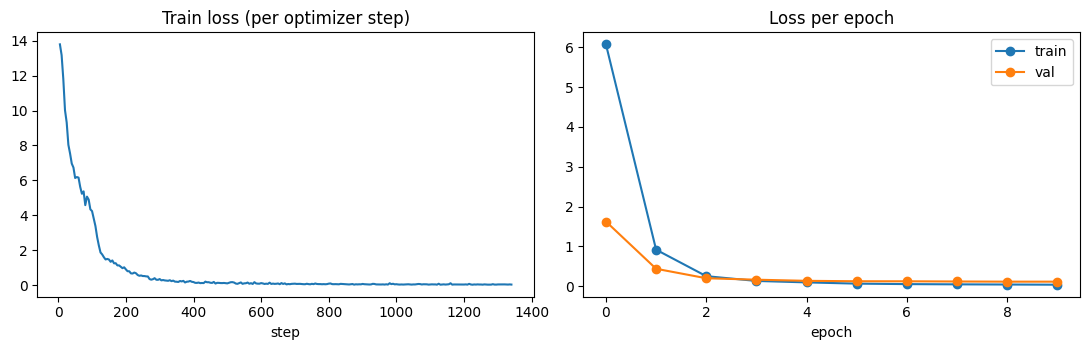

In [ ]:
import matplotlib.pyplot as plt
sl, el = pd.read_csv(f"{OUT}/steps_log.csv"), pd.read_csv(f"{OUT}/epoch_log.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(sl.step, sl.train_loss); ax[0].set_title("Train loss (per optimizer step)"); ax[0].set_xlabel("step")
ax[1].plot(el.epoch, el.train_loss, marker="o", label="train"); ax[1].plot(el.epoch, el.val_loss, marker="o", label="val")
ax[1].set_title("Loss per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/loss_curve.png", dpi=150); plt.show()

## Final evaluation (the numbers for your report)
Loads the best checkpoint and evaluates on the held-out CORD test split, the SROIE hold-out, and synthetic Indian bills. Synthetic scores are an optimistic sanity check, not a real-bill score; report them separately and honestly.

In [15]:
model = VisionEncoderDecoderModel.from_pretrained(f"{OUT}/ckpt_best").to(device)
if "baseline" not in globals():
    baseline = json.load(open(f"{OUT}/baseline_metrics.json"))

final = {}
final["cord_test"], cal, preds = eval_records(RECS["cord_test"])
if USE_SYNTH:
    final["synthetic_indian_val"], cal_s, _ = eval_records(RECS["synth_val"], n=60)
    cal += cal_s
if USE_SROIE:
    final["sroie_holdout_exact_match"] = eval_sroie(150)

cal_df = calibration(cal)
print(pd.DataFrame({"baseline": baseline, "fine-tuned (CORD test)": final["cord_test"]}).to_string())
print({k: v for k, v in final.items() if k != "cord_test"})
print(cal_df.to_string(index=False))

json.dump({"baseline_cord": baseline, "finetuned": final, "calibration": cal_df.to_dict("records"),
           "settings": {"img": [IMG_H, IMG_W], "max_len": MAX_LEN, "epochs": EPOCHS, "lr": LR,
                        "effective_batch": BATCH * ACCUM, "sroie": USE_SROIE, "synthetic": USE_SYNTH}},
          open(f"{OUT}/metrics.json", "w"), indent=1)
json.dump(preds[:20], open(f"{OUT}/sample_predictions.json", "w"), indent=1, default=str)

Loading weights:   0%|          | 0/483 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/60 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

                       baseline  fine-tuned (CORD test)
n                          20.0                100.0000
valid_json_rate             0.0                  0.9800
item_P                      0.0                  0.8809
item_R                      0.0                  0.8313
item_F1                     0.0                  0.8554
charge_P                    0.0                  0.8431
charge_R                    0.0                  0.7818
charge_F1                   0.0                  0.8113
subtotal_acc                0.0                  0.8125
grand_total_acc             0.0                  0.9462
pred_arith_consistent       0.0                  0.7200
{'synthetic_indian_val': {'n': 60, 'valid_json_rate': 1.0, 'item_P': 1.0, 'item_R': 1.0, 'item_F1': 1.0, 'charge_P': 1.0, 'charge_R': 1.0, 'charge_F1': 1.0, 'subtotal_acc': 1.0, 'grand_total_acc': 1.0, 'pred_arith_consistent': 1.0}, 'sroie_holdout_exact_match': {'company': 0.8533, 'date': 0.9067, 'address': 0.5, 'total': 0.853

## Your own real bills (most important number for the Indian-bill test)
Photograph 15-20 real hostel/restaurant bills. Put them in a Drive folder named `my-real-bills` together with `labels.json`:
`{"bill1.jpg": {"items": [{"name": "...", "qty": 1, "unit_price": 220, "total": 220}], "charges": [{"type": "CGST", "amount": 18.5}], "subtotal": 740, "grand_total": 767}, ...}`
Use the same charge names as above (CGST, SGST, Service Charge, Discount, Round Off).

In [ ]:
REAL_DIR = "/content/drive/MyDrive/my-real-bills"  
if os.path.exists(f"{REAL_DIR}/labels.json"):
    labels = json.load(open(f"{REAL_DIR}/labels.json"))
    real = [{"src": "file", "path": f"{REAL_DIR}/{fn}", "gt": gt} for fn, gt in labels.items()]
    real_agg, real_cal, real_preds = eval_records(real)
    print(real_agg); print(calibration(real_cal).to_string(index=False))
    json.dump({"real_bills": real_agg}, open(f"{OUT}/real_bills_metrics.json", "w"), indent=1)
    json.dump(real_preds, open(f"{OUT}/real_bills_predictions.json", "w"), indent=1, default=str)
else:
    print("No real-bill folder yet. Add one later and re-run this cell.")

  0%|          | 0/4 [00:00<?, ?it/s]

{'n': 4, 'valid_json_rate': 0.25, 'item_P': 0.3333, 'item_R': 0.0625, 'item_F1': 0.1053, 'charge_P': 0.0, 'charge_R': 0.0, 'charge_F1': 0.0, 'subtotal_acc': 0.0, 'grand_total_acc': 0.0, 'pred_arith_consistent': 0.0}
min_token_conf  fields  accuracy
     0.00-0.50       4     0.000
     0.50-0.80       6     0.333
     0.80-0.95       2     0.500
     0.95-1.00       4     0.500


In [ ]:
r = RECS["cord_test"][0]
gen, probs = infer(load_image(r), "bill")
js, conf, seq = decode(gen, probs)
print(json.dumps(norm_pred(js), indent=1)[:1200])
print("FLAGGED FOR CORRECTION (min token prob < %.2f):" % LOW_CONF,
      {p: round(c["min"], 2) for p, c in conf.items() if c["min"] < LOW_CONF})

{
 "items": [
  {
   "name": "- TICKET CP",
   "qty": 2,
   "unit_price": 60000,
   "total": 80000
  }
 ],
 "charges": [
  {
   "type": "Tax",
   "amount": 5455
  }
 ],
 "subtotal": -60000,
 "grand_total": 60000
}
FLAGGED FOR CORRECTION (min token prob < 0.80): {'items[0].qty': 0.76, 'items[0].total': 0.73}


In [ ]:
print(OUT)
!ls -la "{OUT}"
!ls -la /content/drive/MyDrive | head -30

/content/drive/MyDrive/splitsnap_run1
total 119
drwx------ 4 root root  4096 Oct  8 11:32 .
drwx------ 4 root root  4096 Oct  8 08:31 ..
-rw------- 1 root root   219 Oct  8 08:34 baseline_metrics.json
drwx------ 2 root root  4096 Oct  8 11:25 ckpt_best
drwx------ 2 root root  4096 Oct  8 11:26 ckpt_last
-rw------- 1 root root   232 Oct  8 11:25 epoch_log.csv
-rw------- 1 root root 54199 Oct  8 11:26 loss_curve.png
-rw------- 1 root root  1457 Oct  8 11:32 metrics.json
-rw------- 1 root root 42041 Oct  8 11:32 sample_predictions.json
-rw------- 1 root root  5432 Oct  8 11:25 steps_log.csv
total 27038
drwx------ 4 root root     4096 Oct  8 08:31 .
drwx------ 5 root root     4096 Oct  8 08:31 ..
-rw------- 1 root root 11292433 May 29 05:46 Aditya_IronLot.zip
-rw------- 1 root root     5209 May 29 05:49 agent_Aditya.py
-rw------- 1 root root  1188957 Jun 12 11:54 Airline Loyalty Program Project.zip
-rw------- 1 root root  1154448 May 29 05:48 analysis_Aditya.ipynb
drwx------ 2 root root   